In [1]:
import os
os.environ["CUDA_VISIBLE_DEVICES"] = "-1"

<h3 id="Imports">Imports<a class="anchor-link" href="#Imports">¶</a></h3>

In [1]:
import tensorflow_datasets as tfds
import tensorflow as tf
from tensorflow.keras.utils import to_categorical

<h3 id="Load-Data">Load Data<a class="anchor-link" href="#Load-Data">¶</a></h3>

In [3]:
## Loading images and labels
(train_ds, train_labels), (test_ds, test_labels) = tfds.load("tf_flowers",
    split=["train[:70%]", "train[:30%]"], ## Train test split
    batch_size=-1,
    as_supervised=True,  # Include labels
)

c:\Users\mores\AppData\Local\Programs\Python\Python313\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Dl Completed...: 100%|██████████| 1/1 [00:56<00:00, 56.68s/ url]


Dataset tf_flowers downloaded and prepared to C:\Users\mores\tensorflow_datasets\tf_flowers\3.0.1. Subsequent calls will reuse this data.



<h3 id="Image-Preprocessing">Image Preprocessing<a class="anchor-link" href="#Image-Preprocessing">¶</a></h3>

In [5]:
## check existing image size
train_ds[0].shape

TensorShape([442, 1024, 3])

In [6]:
## Resizing images
train_ds = tf.image.resize(train_ds, (150, 150))
test_ds = tf.image.resize(test_ds, (150, 150))

In [7]:
train_labels

<tf.Tensor: shape=(2569,), dtype=int64, numpy=array([2, 3, 3, ..., 0, 2, 0], shape=(2569,))>

In [8]:
## Transforming labels to correct format
train_labels = to_categorical(train_labels, num_classes=5)
test_labels = to_categorical(test_labels, num_classes=5)

In [9]:
train_labels[0]

<tf.Tensor: shape=(5,), dtype=float32, numpy=array([0., 0., 1., 0., 0.], dtype=float32)>

<h3 id="Use-Pretrained-VGG16-Image-Classification-model">Use Pretrained VGG16 Image Classification model<a class="anchor-link" href="#Use-Pretrained-VGG16-Image-Classification-model">¶</a></h3>

<h1 id="Load-a-pre-trained-CNN-model-trained-on-a-large-dataset"><strong>Load a pre-trained CNN model trained on a large dataset</strong><a class="anchor-link" href="#Load-a-pre-trained-CNN-model-trained-on-a-large-dataset">¶</a></h1>

In [10]:
from tensorflow.keras.applications.vgg16 import VGG16
from tensorflow.keras.applications.vgg16 import preprocess_input

In [11]:
train_ds[0].shape

TensorShape([150, 150, 3])

In [12]:
## Loading VGG16 model
base_model = VGG16(weights="imagenet", include_top=False, input_shape=train_ds[0].shape)

58889256/58889256 ━━━━━━━━━━━━━━━━━━━━ 16s 0us/step


In [13]:
## will not train base mode
# Freeze Parameters in model's lower convolutional layers
base_model.trainable = False 

In [14]:
## Preprocessing input
train_ds = preprocess_input(train_ds) 
test_ds = preprocess_input(test_ds)

In [15]:
## model details
base_model.summary()

Model: "vgg16"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 150, 150, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv1 (Conv2D)           │ (None, 150, 150, 64)   │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv2 (Conv2D)           │ (None, 150, 150, 64)   │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_pool (MaxPooling2D)      │ (None, 75, 75, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv1 (Conv2D)           │ (None, 75, 75, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv2 (Conv2D)           │ (None, 75, 75, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_pool (MaxPooling2D)      │ (None, 37, 37, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv1 (Conv2D)           │ (None, 37, 37, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv2 (Conv2D)           │ (None, 37, 37, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv3 (Conv2D)           │ (None, 37, 37, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_pool (MaxPooling2D)      │ (None, 18, 18, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv1 (Conv2D)           │ (None, 18, 18, 512)    │     1,180,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv2 (Conv2D)           │ (None, 18, 18, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv3 (Conv2D)           │ (None, 18, 18, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_pool (MaxPooling2D)      │ (None, 9, 9, 512)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv1 (Conv2D)           │ (None, 9, 9, 512)      │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv2 (Conv2D)           │ (None, 9, 9, 512)      │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv3 (Conv2D)           │ (None, 9, 9, 512)      │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_pool (MaxPooling2D)      │ (None, 4, 4, 512)      │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,714,688 (56.13 MB)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 14,714,688 (56.13 MB)

<p><strong>Add custom classifier with two dense layers of trainable parameters to model</strong></p>

In [16]:
#add our layers on top of this model
from tensorflow.keras import layers, models

flatten_layer = layers.Flatten()
dense_layer_1 = layers.Dense(50, activation='relu')
dense_layer_2 = layers.Dense(20, activation='relu')
prediction_layer = layers.Dense(5, activation='softmax')


model = models.Sequential([
    base_model,
    flatten_layer,
    dense_layer_1,
    dense_layer_2,
    prediction_layer
])

<p><strong>Train classifier layers on training data available for task</strong></p>

In [17]:
from tensorflow.keras.callbacks import EarlyStopping

model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy'],
)

In [18]:
es = EarlyStopping(monitor='val_accuracy', mode='max', patience=5,  restore_best_weights=True)

In [19]:
history=model.fit(train_ds, train_labels, epochs=50, validation_split=0.2, batch_size=32, callbacks=[es])

Epoch 1/50
65/65 ━━━━━━━━━━━━━━━━━━━━ 72s 1s/step - accuracy: 0.4925 - loss: 2.0256 - val_accuracy: 0.6051 - val_loss: 1.0409
Epoch 2/50
65/65 ━━━━━━━━━━━━━━━━━━━━ 66s 1s/step - accuracy: 0.7158 - loss: 0.7644 - val_accuracy: 0.6518 - val_loss: 0.9993
Epoch 3/50
65/65 ━━━━━━━━━━━━━━━━━━━━ 67s 1s/step - accuracy: 0.7961 - loss: 0.5597 - val_accuracy: 0.6498 - val_loss: 0.9751
Epoch 4/50
65/65 ━━━━━━━━━━━━━━━━━━━━ 65s 1s/step - accuracy: 0.8472 - loss: 0.3965 - val_accuracy: 0.6751 - val_loss: 1.0471
Epoch 5/50
65/65 ━━━━━━━━━━━━━━━━━━━━ 82s 1s/step - accuracy: 0.8934 - loss: 0.3059 - val_accuracy: 0.6770 - val_loss: 1.1443
Epoch 6/50
65/65 ━━━━━━━━━━━━━━━━━━━━ 65s 995ms/step - accuracy: 0.9134 - loss: 0.2461 - val_accuracy: 0.6790 - val_loss: 1.1578
Epoch 7/50
65/65 ━━━━━━━━━━━━━━━━━━━━ 69s 1s/step - accuracy: 0.9489 - loss: 0.1715 - val_accuracy: 0.6926 - val_loss: 1.2689
Epoch 8/50
65/65 ━━━━━━━━━━━━━━━━━━━━ 67s 1s/step - accuracy: 0.9645 - loss: 0.1239 - val_accuracy: 0.7062 - val_lo

In [20]:
los,accurac=model.evaluate(test_ds,test_labels)
print("Loss: ",los,"Accuracy: ", accurac)

35/35 ━━━━━━━━━━━━━━━━━━━━ 30s 840ms/step - accuracy: 0.9791 - loss: 0.0897
Loss:  0.08965573459863663 Accuracy:  0.9791098833084106


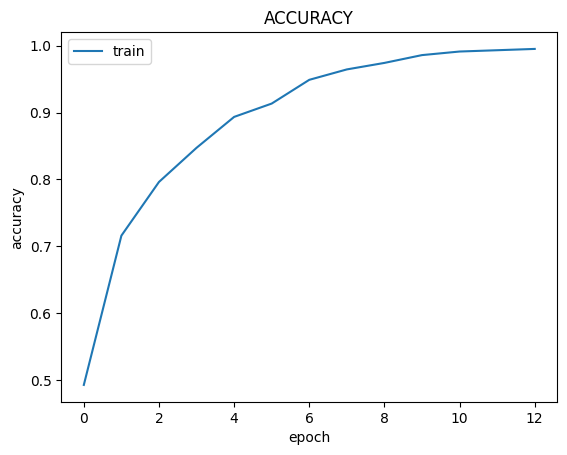

In [21]:
import matplotlib.pyplot as plt
plt.plot(history.history['accuracy'])
plt.title('ACCURACY')
plt.ylabel('accuracy')
plt.xlabel('epoch')
plt.legend(['train'],loc='upper left')
plt.show()

In [22]:
import numpy as np
import pandas as pd
y_pred = model.predict(test_ds)
y_classes = [np.argmax(element) for element in y_pred]
#to_categorical(y_classes, num_classes=5)
#to_categorical(test_labels, num_classes=5)
print(y_classes[:10])
print("\nTest")
print(test_labels[:10])

35/35 ━━━━━━━━━━━━━━━━━━━━ 30s 853ms/step
[np.int64(2), np.int64(3), np.int64(3), np.int64(4), np.int64(3), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(1)]

Test
tf.Tensor(
[[0. 0. 1. 0. 0.]
 [0. 0. 0. 1. 0.]
 [0. 0. 0. 1. 0.]
 [0. 0. 0. 0. 1.]
 [0. 0. 0. 1. 0.]
 [1. 0. 0. 0. 0.]
 [1. 0. 0. 0. 0.]
 [1. 0. 0. 0. 0.]
 [1. 0. 0. 0. 0.]
 [0. 1. 0. 0. 0.]], shape=(10, 5), dtype=float32)
